# Brain Tumor MRI Classification — Vision Transformer (Transfer Learning)

Classifies MRI scans into **glioma, meningioma, pituitary, notumor** using an ImageNet-pretrained **Swin Transformer (Swin-T)** or **ViT-B/16**.

This is the transformer counterpart of `brain_tumor_cnn.ipynb`. Data loading, 5-fold cross-validation, early stopping and evaluation are identical, so the two models can be compared fairly.

**Before running:** Runtime → Change runtime type → select **GPU** (T4 is fine). Transformers are heavier than ResNet18: expect each epoch to take noticeably longer. Lower `EPOCHS` or `K_FOLDS` if Colab runs out of time.

This notebook expects your dataset zipped with this structure inside:
```
Training/glioma/*.jpg
Training/meningioma/*.jpg
Training/notumor/*.jpg
Training/pituitary/*.jpg
Testing/glioma/*.jpg
Testing/meningioma/*.jpg
Testing/notumor/*.jpg
Testing/pituitary/*.jpg
```

## 1. Check GPU

In [1]:
import torch
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU detected — go to Runtime > Change runtime type > GPU')

CUDA available: True
GPU: Tesla T4


## 2. Install dependencies

In [2]:
!pip install -q torch torchvision scikit-learn matplotlib pillow

## 3. Upload and unzip your dataset

Zip your `Training/` and `Testing/` folders together into one file (e.g. `archive.zip`) before uploading, so the structure matches what's described above.

In [3]:
from google.colab import files
uploaded = files.upload()  # select your archive.zip

Saving archive.zip to archive.zip


In [4]:
import zipfile, os, glob

zip_name = list(uploaded.keys())[0]
os.makedirs('data', exist_ok=True)
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('data')

# Sanity check: print class folders found
for split in ['Training', 'Testing']:
    root = os.path.join('data', split)
    if os.path.isdir(root):
        for cls in sorted(os.listdir(root)):
            n = len(glob.glob(os.path.join(root, cls, '*')))
            print(split, cls, n)

Training glioma 1400
Training meningioma 1400
Training notumor 1400
Training pituitary 1400
Testing glioma 400
Testing meningioma 400
Testing notumor 400
Testing pituitary 400


If the folder names above don't say `Training`/`Testing` directly (e.g. there's an extra nested folder from the zip), adjust `DATA_DIR` in the next section accordingly — print `os.listdir('data')` to check.

## 4. Imports and config

In [5]:
import copy, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import KFold
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

DATA_DIR = 'data'       # change if your extracted folder is nested differently
BACKBONE = 'swin_t'     # 'swin_t' (28M params) or 'vit_b_16' (86M params, needs more GPU memory)
EPOCHS = 10             # transformers converge fast when fine-tuned; each epoch is slower than ResNet18
BATCH_SIZE = 32         # use 16 if you hit a CUDA out-of-memory error (especially with vit_b_16)
LR = 1e-4               # lower than the CNN (3e-4): transformers are sensitive to large learning rates
WEIGHT_DECAY = 0.05     # standard for transformer fine-tuning
IMG_SIZE = 224          # ViT-B/16 requires exactly 224
K_FOLDS = 5
PATIENCE = 3
USE_AMP = True          # mixed precision: faster and lighter on GPU (ignored on CPU)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = USE_AMP and device.type == 'cuda'
print('Using device:', device, '| mixed precision:', USE_AMP)

Using device: cuda | mixed precision: True


## 5. Model definition (transformer)

In [6]:
def build_model(backbone: str, num_classes: int = 4):
    """Transfer-learning model: pretrained ImageNet transformer + new classifier head."""
    if backbone == 'swin_t':
        model = models.swin_t(weights=models.Swin_T_Weights.IMAGENET1K_V1)
        in_feats = model.head.in_features
        model.head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_feats, num_classes),
        )
    elif backbone == 'vit_b_16':
        model = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
        in_feats = model.heads.head.in_features
        model.heads = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_feats, num_classes),
        )
    else:
        raise ValueError(f'Unknown backbone: {backbone}')
    return model

n_params = sum(p.numel() for p in build_model(BACKBONE).parameters()) / 1e6
print(f'{BACKBONE}: {n_params:.1f}M parameters')

Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 164MB/s] 


swin_t: 27.5M parameters


## 6. Data loading

In [7]:
def get_dataloaders_cv(data_dir, img_size=224, batch_size=32, num_workers=2):
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats

    train_tf = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),  # MRI is grayscale; replicate to 3ch
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.3),
        transforms.RandomRotation(10),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    eval_tf = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    full_train_dataset = datasets.ImageFolder(f'{data_dir}/Training', transform=train_tf)
    full_val_dataset = datasets.ImageFolder(f'{data_dir}/Training', transform=eval_tf)
    test_set = datasets.ImageFolder(f'{data_dir}/Testing', transform=eval_tf)

    assert full_train_dataset.classes == test_set.classes, 'Train/Test class order mismatch!'

    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    return full_train_dataset, full_val_dataset, test_loader, full_train_dataset.classes

full_train_dataset, full_val_dataset, test_loader, classes = get_dataloaders_cv(
    DATA_DIR, img_size=IMG_SIZE, batch_size=BATCH_SIZE
)
print('Classes:', classes)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [8]:
class EarlyStopping:
    def __init__(self, patience=3, delta=0.001):
        self.patience = patience
        self.delta = delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.delta:
            self.counter += 1
            print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

## 7. Training loop

In [9]:
def train_cv(full_train_ds, full_val_ds, backbone, classes, device, k_folds=5, epochs=10,
             lr=1e-4, weight_decay=0.05, patience=3, use_amp=False):
    kfold = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    overall_best_acc = 0.0
    overall_best_state = None
    best_fold_history = None

    for fold, (train_ids, val_ids) in enumerate(kfold.split(full_train_ds)):
        print(f'\n========== FOLD {fold + 1}/{k_folds} ==========')

        train_sub = Subset(full_train_ds, train_ids)
        val_sub = Subset(full_val_ds, val_ids)

        train_loader = DataLoader(train_sub, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
        val_loader = DataLoader(val_sub, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

        model = build_model(backbone, num_classes=len(classes)).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
        scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
        early_stopping = EarlyStopping(patience=patience)

        history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
        fold_best_acc = 0.0

        for epoch in range(epochs):
            t0 = time.time()
            model.train()
            running_loss, running_correct, n = 0.0, 0, 0
            for imgs, labels in train_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.autocast(device_type=device.type, enabled=use_amp):
                    outputs = model(imgs)
                    loss = criterion(outputs, labels)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # stabilises transformer fine-tuning
                scaler.step(optimizer)
                scaler.update()
                running_loss += loss.item() * imgs.size(0)
                running_correct += (outputs.argmax(1) == labels).sum().item()
                n += imgs.size(0)
            train_loss, train_acc = running_loss / n, running_correct / n

            model.eval()
            v_loss, v_correct, vn = 0.0, 0, 0
            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs, labels = imgs.to(device), labels.to(device)
                    with torch.autocast(device_type=device.type, enabled=use_amp):
                        outputs = model(imgs)
                        loss = criterion(outputs, labels)
                    v_loss += loss.item() * imgs.size(0)
                    v_correct += (outputs.argmax(1) == labels).sum().item()
                    vn += imgs.size(0)
            val_loss, val_acc = v_loss / vn, v_correct / vn
            scheduler.step(val_acc)

            history['train_loss'].append(train_loss)
            history['val_loss'].append(val_loss)
            history['train_acc'].append(train_acc)
            history['val_acc'].append(val_acc)

            if val_acc > fold_best_acc:
                fold_best_acc = val_acc
                if fold_best_acc > overall_best_acc:
                    overall_best_acc = fold_best_acc
                    overall_best_state = copy.deepcopy(model.state_dict())
                    best_fold_history = copy.deepcopy(history)

            print(f'Epoch {epoch+1:2d}/{epochs} | '
                  f'train_loss {train_loss:.4f} acc {train_acc:.4f} | '
                  f'val_loss {val_loss:.4f} acc {val_acc:.4f} | '
                  f'{time.time()-t0:.1f}s')

            # Early Stopping Check
            early_stopping(val_loss)
            if early_stopping.early_stop:
                print(f"Early stopping triggered at epoch {epoch+1}")
                break

        del model, optimizer  # free GPU memory before the next fold
        if device.type == 'cuda':
            torch.cuda.empty_cache()

    # Load overall best model across all folds
    best_model = build_model(backbone, num_classes=len(classes)).to(device)
    best_model.load_state_dict(overall_best_state)
    return best_model, best_fold_history, overall_best_acc

t_start = time.time()
model, history, best_val_acc = train_cv(
    full_train_dataset, full_val_dataset, BACKBONE, classes, device,
    k_folds=K_FOLDS, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY,
    patience=PATIENCE, use_amp=USE_AMP
)
print(f'\nBest validation accuracy across all folds: {best_val_acc:.4f}')
print(f'Total training time: {(time.time() - t_start) / 60:.1f} min')


========== FOLD 1/5 ==========
Epoch  1/10 | train_loss 0.4111 acc 0.8464 | val_loss 0.1181 acc 0.9536 | 41.9s
Epoch  2/10 | train_loss 0.1458 acc 0.9542 | val_loss 0.0681 acc 0.9777 | 40.8s
Epoch  3/10 | train_loss 0.0950 acc 0.9670 | val_loss 0.0870 acc 0.9741 | 40.4s
EarlyStopping counter: 1 out of 3
Epoch  4/10 | train_loss 0.0729 acc 0.9792 | val_loss 0.0533 acc 0.9839 | 41.4s
Epoch  5/10 | train_loss 0.0828 acc 0.9797 | val_loss 0.1045 acc 0.9759 | 41.5s
EarlyStopping counter: 1 out of 3
Epoch  6/10 | train_loss 0.0524 acc 0.9850 | val_loss 0.0599 acc 0.9875 | 41.2s
EarlyStopping counter: 2 out of 3
Epoch  7/10 | train_loss 0.0421 acc 0.9897 | val_loss 0.0922 acc 0.9804 | 40.7s
EarlyStopping counter: 3 out of 3
Early stopping triggered at epoch 7

========== FOLD 2/5 ==========
Epoch  1/10 | train_loss 0.3803 acc 0.8609 | val_loss 0.1086 acc 0.9616 | 41.5s
Epoch  2/10 | train_loss 0.1545 acc 0.9484 | val_loss 0.0858 acc 0.9679 | 41.4s
Epoch  3/10 | train_loss 0.1088 acc 0.9701 |

## 8. Evaluate on the held-out test set

In [10]:
def evaluate(model, test_loader, device, classes):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    report = classification_report(all_labels, all_preds, target_names=classes, digits=3)
    cm = confusion_matrix(all_labels, all_preds)
    return acc, report, cm

acc, report, cm = evaluate(model, test_loader, device, classes)
print(f'Test accuracy: {acc:.4f}\n')
print(report)

Test accuracy: 0.9537

              precision    recall  f1-score   support

      glioma      1.000     0.835     0.910       400
  meningioma      0.893     0.980     0.934       400
     notumor      0.957     1.000     0.978       400
   pituitary      0.978     1.000     0.989       400

    accuracy                          0.954      1600
   macro avg      0.957     0.954     0.953      1600
weighted avg      0.957     0.954     0.953      1600



## 9. Plots

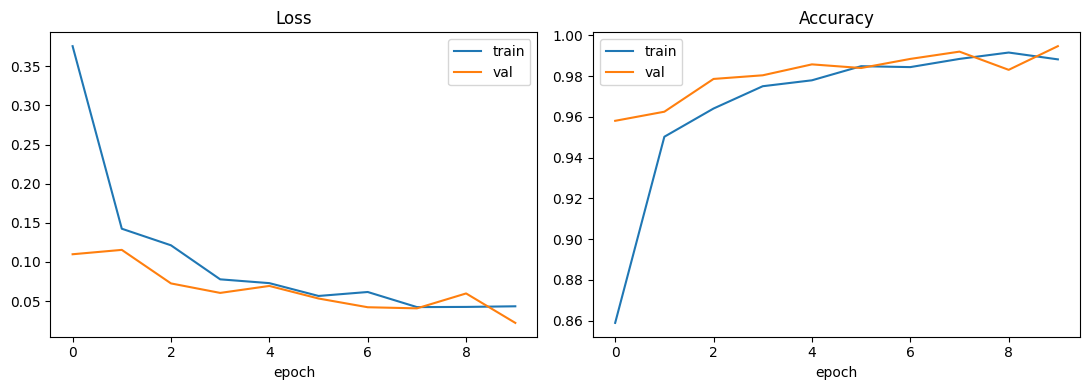

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(history['train_acc'], label='train')
axes[1].plot(history['val_acc'], label='val')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig('training_curves_transformer.png', dpi=150)
plt.show()

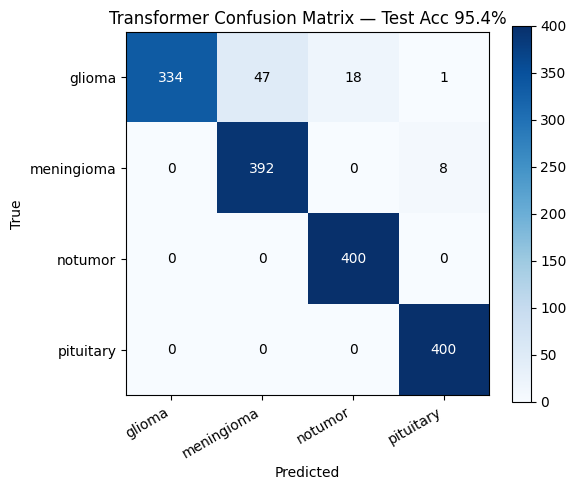

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=30, ha='right')
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title(f'Transformer Confusion Matrix — Test Acc {acc:.1%}')
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im)
plt.tight_layout()
plt.savefig('confusion_matrix_transformer.png', dpi=150)
plt.show()

## 10. Save the model + download results

In [13]:
torch.save({'model_state': model.state_dict(), 'classes': classes, 'backbone': BACKBONE},
           'best_model_transformer.pt')
with open('classification_report_transformer.txt', 'w') as f:
    f.write(f'Test accuracy: {acc:.4f}\n\n{report}')

print('Saved: best_model_transformer.pt, training_curves_transformer.png, confusion_matrix_transformer.png, classification_report_transformer.txt')

Saved: best_model_transformer.pt, training_curves_transformer.png, confusion_matrix_transformer.png, classification_report_transformer.txt


In [14]:
from google.colab import files
files.download('best_model_transformer.pt')
files.download('confusion_matrix_transformer.png')
files.download('training_curves_transformer.png')
files.download('classification_report_transformer.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Predict on a new image

Run this cell after training (or after re-loading `best_model.pt`) to classify a single new MRI.

In [15]:
import torch.nn.functional as F
from PIL import Image

def predict_image(image_path, model, classes, img_size=224, device='cpu'):
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    tf = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    img = Image.open(image_path).convert('RGB')
    x = tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0]
    pred_idx = int(probs.argmax())
    print(f'Predicted: {classes[pred_idx]} ({probs[pred_idx]:.1%} confidence)')
    for cls, p in sorted(zip(classes, probs.tolist()), key=lambda t: -t[1]):
        print(f'  {cls:12s} {p:.1%}')

# Example — uncomment and set a path to try it:
# predict_image('data/Testing/glioma/Te-gl_1.jpg', model, classes, img_size=IMG_SIZE, device=device)